# ✈️ Flight Price Prediction using Machine Learning
### Predictive Analytics Project

**Dataset:** Flight Price Prediction (EaseMyTrip) — 3,00,153 rows, 12 columns
**Source:** Kaggle — [shubhambathwal/flight-price-prediction](https://www.kaggle.com/datasets/shubhambathwal/flight-price-prediction)
The data was scraped from the EaseMyTrip website for flights between 6 major Indian metro cities (Feb–Mar 2022).

**Objective:** Predict the ticket `price` of a flight using airline, source/destination city, departure time, stops, class, duration and days left before departure.

**Steps followed:**
1. Importing libraries & loading data
2. Data Cleaning
3. Exploratory Data Analysis (EDA)
4. Feature Engineering / Encoding
5. Model Building (5 models)
6. Model Comparison — R² Score, MSE, RMSE, MAE
7. Conclusion

## 1. Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 2. Loading the Dataset

In [2]:
df = pd.read_csv('Clean_Dataset.csv')
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [3]:
print("Shape of data:", df.shape)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])

Shape of data: (300153, 12)
Rows: 300153 | Columns: 12


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  str    
 2   flight            300153 non-null  str    
 3   source_city       300153 non-null  str    
 4   departure_time    300153 non-null  str    
 5   stops             300153 non-null  str    
 6   arrival_time      300153 non-null  str    
 7   destination_city  300153 non-null  str    
 8   class             300153 non-null  str    
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 27.5 MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,300153.0,150076.000000,86646.852011,0.00,75038.00,150076.00,225114.00,300152.00
duration,300153.0,12.221021,7.191997,0.83,6.83,11.25,16.17,49.83
days_left,300153.0,26.004751,13.561004,1.00,15.00,26.00,38.00,49.00
price,300153.0,20889.660523,22697.767366,1105.00,4783.00,7425.00,42521.00,123071.00


In [6]:
# unique values in each column
df.nunique()

Unnamed: 0          300153
airline                  6
flight                1561
source_city              6
departure_time           6
stops                    3
arrival_time             6
destination_city         6
class                    2
duration               476
days_left               49
price                12157
dtype: int64

## 3. Data Cleaning

**3.1 Removing unnecessary columns** — `Unnamed: 0` is just the index. `flight` is the flight code (like SG-8709), it has 1500+ unique values and the airline info is already in `airline` column, so dropping both.

In [7]:
df = df.drop(['Unnamed: 0', 'flight'], axis=1)
df.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


**3.2 Missing values**

In [8]:
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

airline             0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64



Total missing values: 0


No missing values in the dataset 👍

**3.3 Duplicate rows**

In [9]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 2213


Shape after removing duplicates: (297940, 10)


**3.4 Checking categories for spelling issues / wrong values**

In [10]:
for col in df.select_dtypes(include='object').columns:
    print(col, ':', df[col].unique())

airline : <StringArray>
['SpiceJet', 'AirAsia', 'Vistara', 'GO_FIRST', 'Indigo', 'Air_India']
Length: 6, dtype: str
source_city : <StringArray>
['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai']
Length: 6, dtype: str
departure_time : <StringArray>
['Evening', 'Early_Morning', 'Morning', 'Afternoon', 'Night', 'Late_Night']
Length: 6, dtype: str
stops : <StringArray>
['zero', 'one', 'two_or_more']
Length: 3, dtype: str
arrival_time : <StringArray>
['Night', 'Morning', 'Early_Morning', 'Afternoon', 'Evening', 'Late_Night']
Length: 6, dtype: str
destination_city : <StringArray>
['Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai', 'Delhi']
Length: 6, dtype: str
class : <StringArray>
['Economy', 'Business']
Length: 2, dtype: str


All categories look clean. Source and destination are never same? Lets check.

In [11]:
print("Rows where source = destination:", (df['source_city'] == df['destination_city']).sum())

Rows where source = destination: 0


**3.5 Outliers**

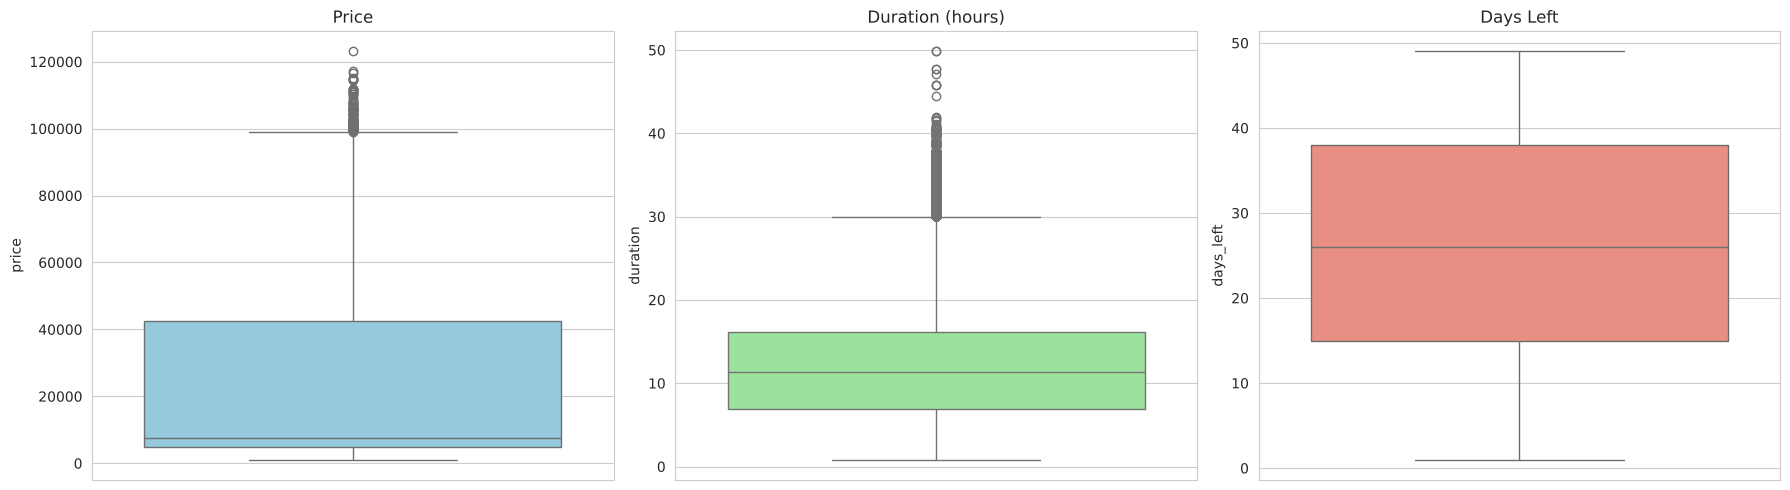

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(y=df['price'], ax=axes[0], color='skyblue').set_title('Price')
sns.boxplot(y=df['duration'], ax=axes[1], color='lightgreen').set_title('Duration (hours)')
sns.boxplot(y=df['days_left'], ax=axes[2], color='salmon').set_title('Days Left')
plt.tight_layout()
plt.show()

Price looks like it has outliers, but that is because of **Business class** tickets (they are much costlier) — so these are real values, not errors.
Duration has some very long flights (40+ hours with multiple stops). Removing extreme duration outliers using IQR.

In [13]:
Q1 = df['duration'].quantile(0.25)
Q3 = df['duration'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print("Upper limit for duration:", round(upper, 2), "hours")

before = df.shape[0]
df = df[df['duration'] <= upper]
print("Removed", before - df.shape[0], "outlier rows")
print("Final shape:", df.shape)

Upper limit for duration: 30.05 hours
Removed 2226 outlier rows
Final shape: (295714, 10)


## 4. Exploratory Data Analysis (EDA)

### 4.1 Distribution of Ticket Price

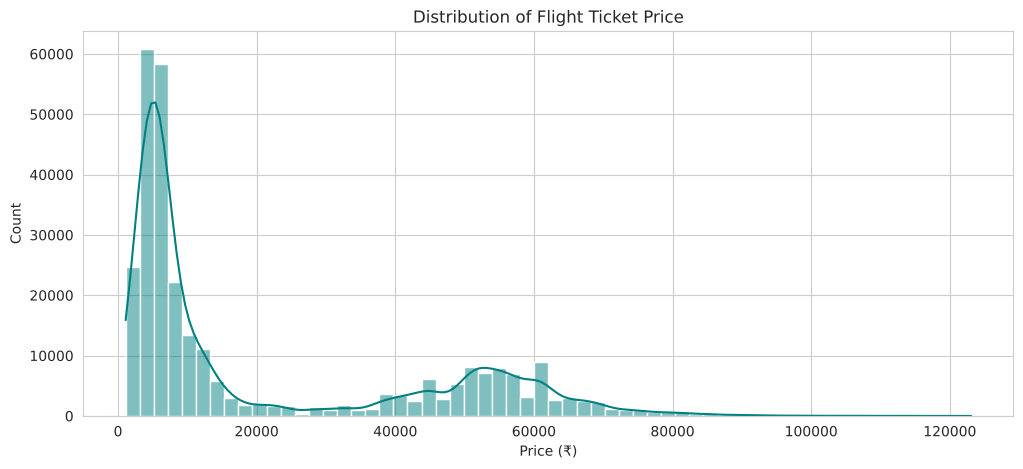

In [14]:
plt.figure(figsize=(12,5))
sns.histplot(df['price'], bins=60, kde=True, color='teal')
plt.title('Distribution of Flight Ticket Price')
plt.xlabel('Price (₹)')
plt.show()

Two peaks are clearly visible — one for **Economy** (₹2k–15k) and one for **Business** (₹40k–70k).

### 4.2 Economy vs Business Class

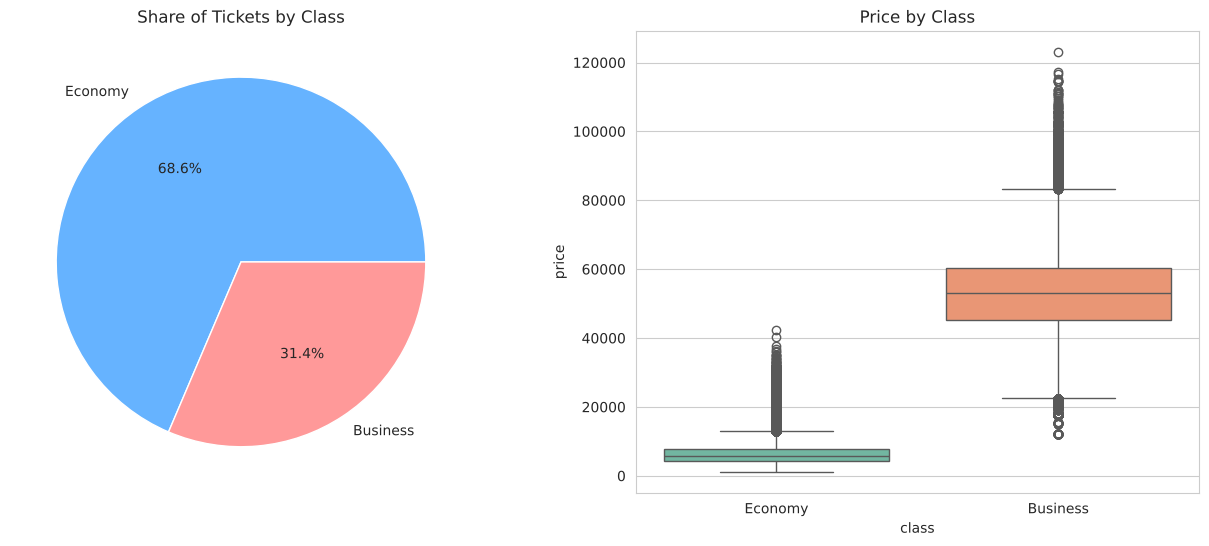

class
Business    52570.0
Economy      6547.0
Name: price, dtype: float64

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
df['class'].value_counts().plot(kind='pie', autopct='%1.1f%%', ax=axes[0], colors=['#66b3ff', '#ff9999'])
axes[0].set_title('Share of Tickets by Class')
axes[0].set_ylabel('')
sns.boxplot(x='class', y='price', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Price by Class')
plt.show()

df.groupby('class')['price'].mean().round(0)

Business class tickets are around **8-9 times costlier** than economy on average.

### 4.3 Airline wise analysis

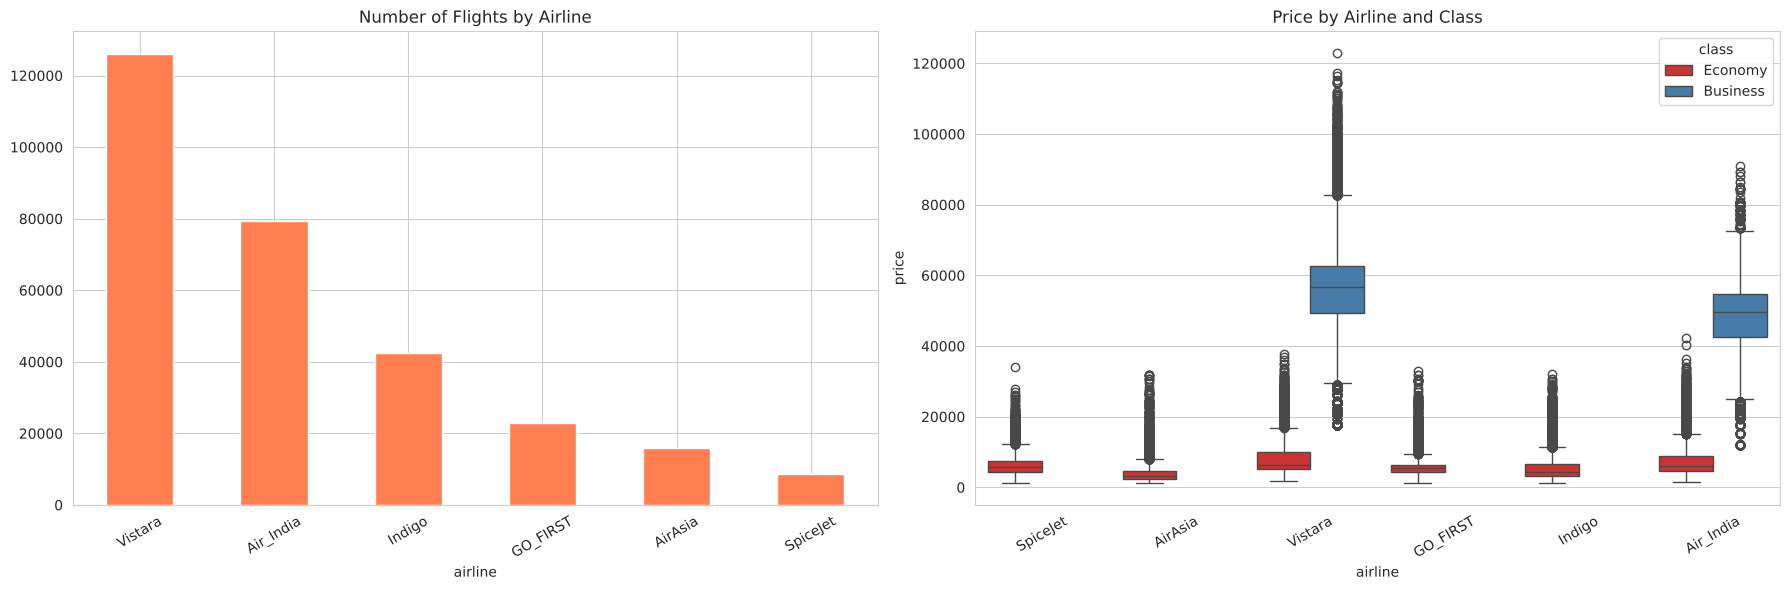

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
df['airline'].value_counts().plot(kind='bar', color='coral', ax=axes[0])
axes[0].set_title('Number of Flights by Airline')
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(x='airline', y='price', hue='class', data=df, ax=axes[1], palette='Set1')
axes[1].set_title('Price by Airline and Class')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

Vistara and Air India have the most flights and are the only airlines offering business class. AirAsia and Indigo are the cheapest.

### 4.4 How price changes with Days Left before departure

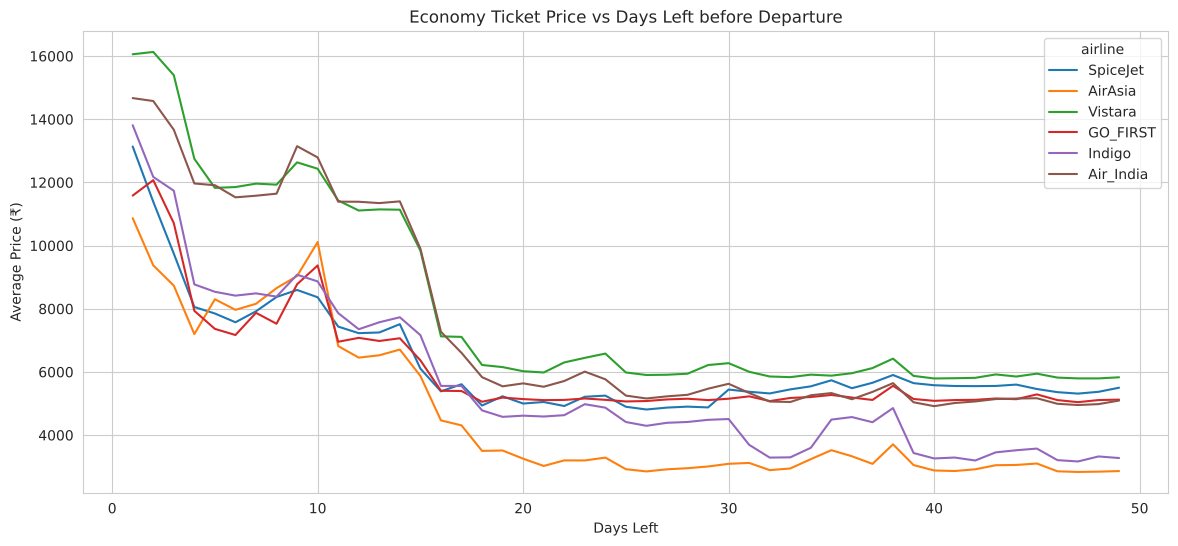

In [17]:
plt.figure(figsize=(14, 6))
sns.lineplot(x='days_left', y='price', data=df[df['class']=='Economy'], hue='airline', ci=None)
plt.title('Economy Ticket Price vs Days Left before Departure')
plt.xlabel('Days Left')
plt.ylabel('Average Price (₹)')
plt.show()

**Very important insight:** Tickets booked in the **last 1-2 weeks are much costlier**. Prices are lowest when booked 15+ days in advance. So booking early really saves money!

### 4.5 Effect of Stops

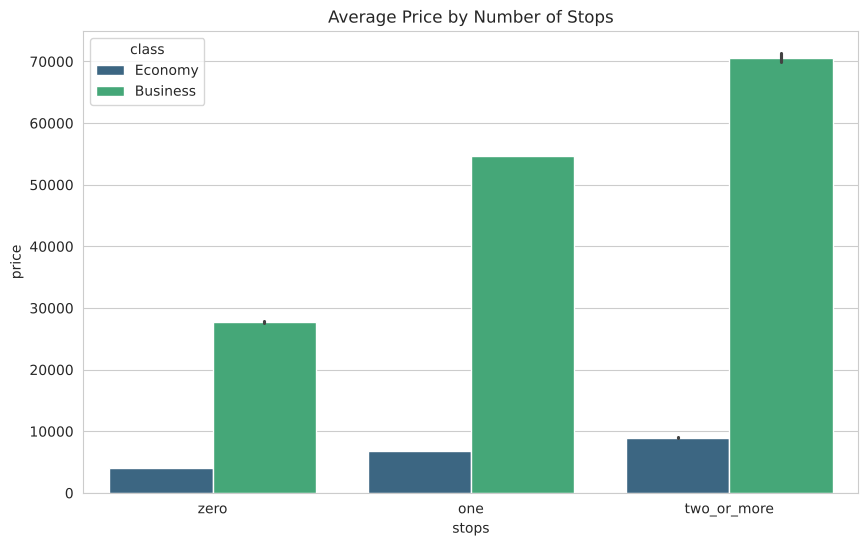

In [18]:
plt.figure(figsize=(10,6))
sns.barplot(x='stops', y='price', hue='class', data=df, order=['zero','one','two_or_more'], palette='viridis')
plt.title('Average Price by Number of Stops')
plt.show()

Surprisingly, non-stop flights are the **cheapest**. One-stop flights are costlier (mostly because full service airlines like Vistara run them).

### 4.6 Departure and Arrival Time

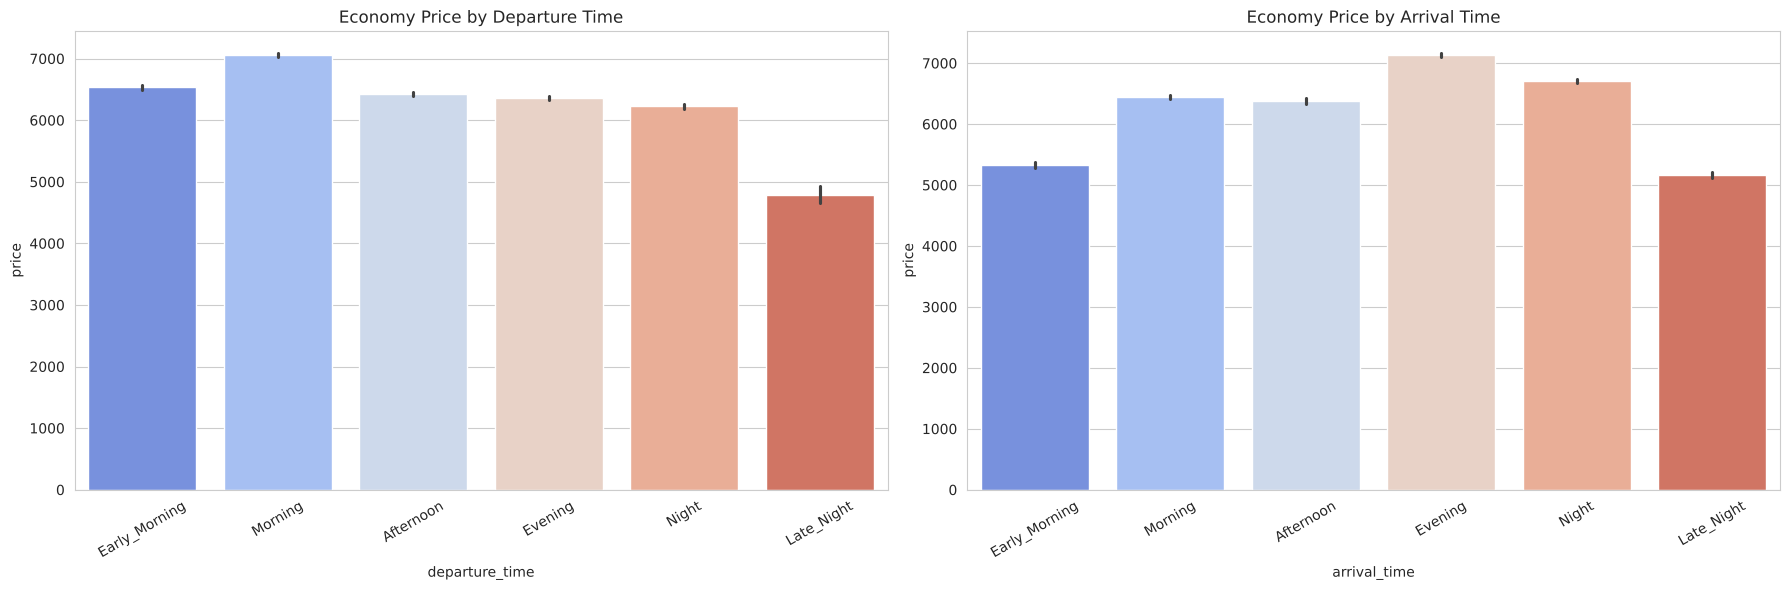

In [19]:
order = ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night']
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.barplot(x='departure_time', y='price', data=df[df['class']=='Economy'], order=order, ax=axes[0], palette='coolwarm')
axes[0].set_title('Economy Price by Departure Time')
axes[0].tick_params(axis='x', rotation=30)
sns.barplot(x='arrival_time', y='price', data=df[df['class']=='Economy'], order=order, ax=axes[1], palette='coolwarm')
axes[1].set_title('Economy Price by Arrival Time')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

Late night flights are the cheapest. Night and evening flights are a bit costlier.

### 4.7 Route wise average price (Source → Destination)

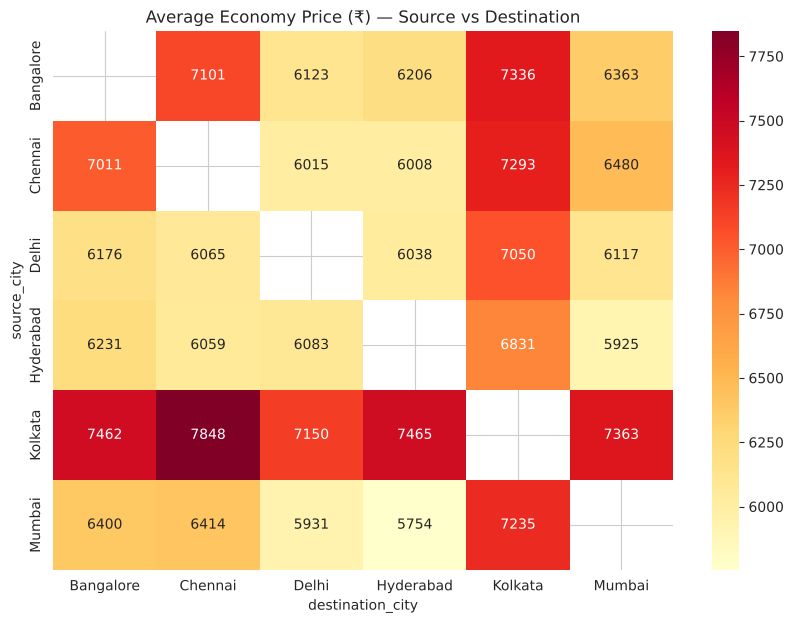

In [20]:
route = df[df['class']=='Economy'].pivot_table(index='source_city', columns='destination_city', values='price', aggfunc='mean')
plt.figure(figsize=(10, 7))
sns.heatmap(route, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Average Economy Price (₹) — Source vs Destination')
plt.show()

Delhi routes are cheapest on average. Chennai and Bangalore routes are among the costliest.

### 4.8 Duration vs Price

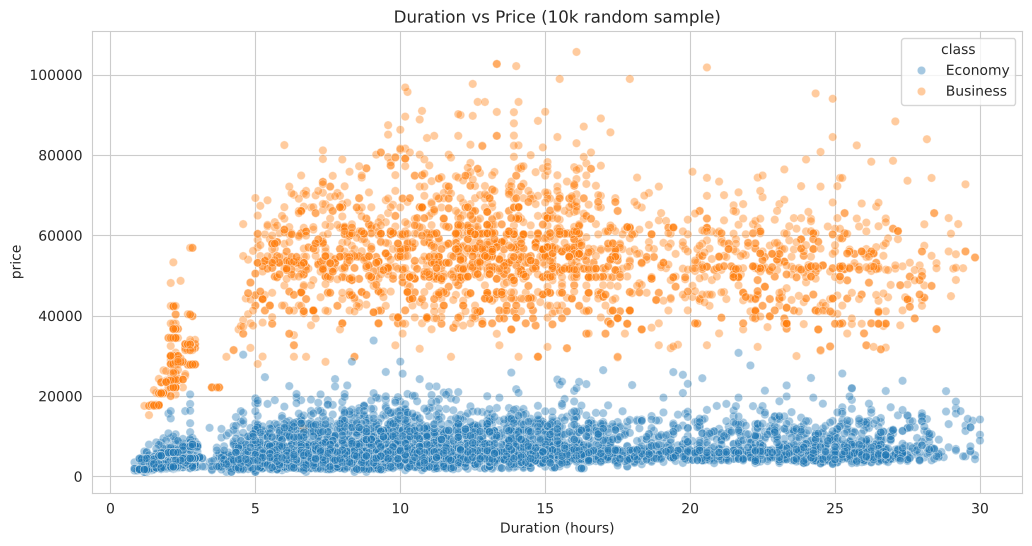

In [21]:
sample = df.sample(10000, random_state=1)
plt.figure(figsize=(12,6))
sns.scatterplot(x='duration', y='price', hue='class', data=sample, alpha=0.4)
plt.title('Duration vs Price (10k random sample)')
plt.xlabel('Duration (hours)')
plt.show()

## 5. Feature Engineering / Encoding

- `class` → binary (Economy = 0, Business = 1)
- `stops` → ordinal (zero = 0, one = 1, two_or_more = 2)
- `airline`, `source_city`, `destination_city`, `departure_time`, `arrival_time` → One Hot Encoding

In [22]:
df['class'] = df['class'].map({'Economy': 0, 'Business': 1})
df['stops'] = df['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2})

df = pd.get_dummies(df, columns=['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time'],
                    drop_first=True, dtype=int)
print("Shape after encoding:", df.shape)
df.head()

Shape after encoding: (295714, 30)


,stops,class,duration,days_left,price,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,...,departure_time_Early_Morning,departure_time_Evening,departure_time_Late_Night,departure_time_Morning,departure_time_Night,arrival_time_Early_Morning,arrival_time_Evening,arrival_time_Late_Night,arrival_time_Morning,arrival_time_Night
0,0,0,2.17,1,5953,0,0,0,1,0,...,0,1,0,0,0,0,0,0,0,1
1,0,0,2.33,1,5953,0,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
2,0,0,2.17,1,5956,0,0,0,0,0,...,1,0,0,0,0,1,0,0,0,0
3,0,0,2.25,1,5955,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
4,0,0,2.33,1,5955,0,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0


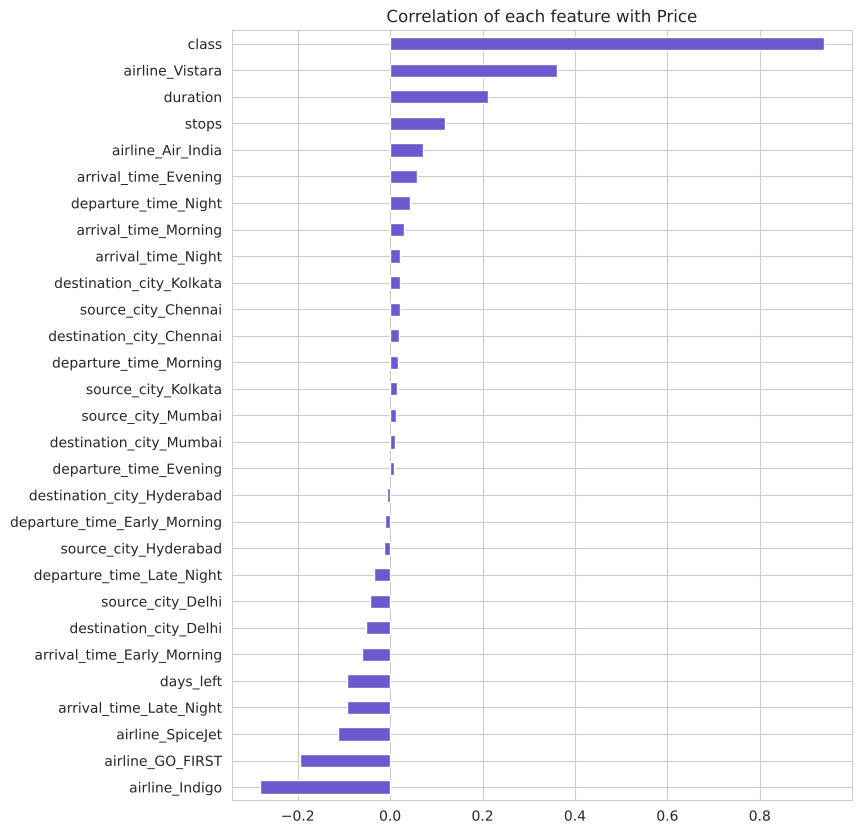

In [23]:
# correlation of features with price
plt.figure(figsize=(8, 10))
df.corr()['price'].drop('price').sort_values().plot(kind='barh', color='slateblue')
plt.title('Correlation of each feature with Price')
plt.show()

`class` has extremely high correlation (~0.94) with price — it is the biggest deciding factor.

## 6. Train Test Split & Scaling

In [24]:
X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (236571, 29)
Testing data: (59143, 29)


In [25]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

## 7. Model Building
Using 5 regression models:
1. Linear Regression
2. Ridge Regression
3. Decision Tree Regressor
4. Random Forest Regressor
5. XGBoost Regressor

In [26]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Decision Tree': DecisionTreeRegressor(max_depth=20, min_samples_leaf=5, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=60, max_depth=25, min_samples_leaf=2, random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(n_estimators=600, learning_rate=0.1, max_depth=8, random_state=42, n_jobs=-1)
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_sc, y_train)
    y_pred = model.predict(X_test_sc)
    predictions[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    train_r2 = r2_score(y_train, model.predict(X_train_sc))

    results.append([name, round(train_r2, 4), round(r2, 4), round(mse, 2), round(rmse, 2), round(mae, 2)])
    print(f"{name} done  ->  R2 = {r2:.4f}")

Linear Regression done  ->  R2 = 0.9096
Ridge Regression done  ->  R2 = 0.9096


Decision Tree done  ->  R2 = 0.9811


Random Forest done  ->  R2 = 0.9864


XGBoost done  ->  R2 = 0.9874


## 8. Model Comparison Table

In [27]:
results_df = pd.DataFrame(results, columns=['Model', 'Train R2', 'Test R2 Score (Accuracy)', 'MSE', 'RMSE', 'MAE'])
results_df['Accuracy (%)'] = (results_df['Test R2 Score (Accuracy)'] * 100).round(2)
results_df = results_df.sort_values('Test R2 Score (Accuracy)', ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1
pd.set_option('display.float_format', '{:,.4f}'.format)
results_df

,Model,Train R2,Test R2 Score (Accuracy),MSE,RMSE,MAE,Accuracy (%)
1,XGBoost,0.9909,0.9874,"6,538,317.0000","2,557.0100","1,341.6900",98.7400
2,Random Forest,0.9941,0.9864,"7,046,288.0700","2,654.4800","1,118.8600",98.6400
3,Decision Tree,0.9869,0.9811,"9,788,738.5700","3,128.7000","1,418.9600",98.1100
4,Linear Regression,0.9102,0.9096,"46,761,202.5800","6,838.2200","4,535.6900",90.9600
5,Ridge Regression,0.9102,0.9096,"46,761,199.4300","6,838.2200","4,535.6900",90.9600


> Note: For regression problems, **R² score** is used as the measure of accuracy (how much % of variation in ticket price the model is able to explain).

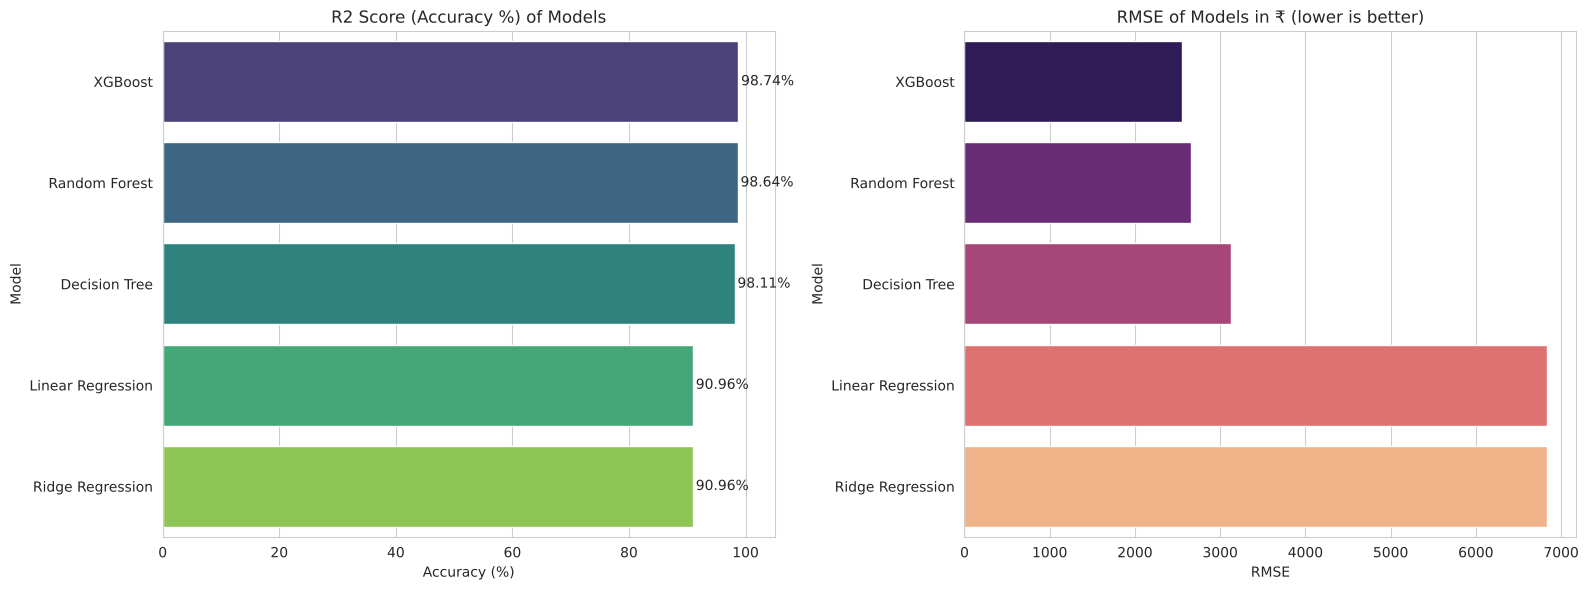

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x='Accuracy (%)', y='Model', data=results_df, ax=axes[0], palette='viridis')
axes[0].set_title('R2 Score (Accuracy %) of Models')
for i, v in enumerate(results_df['Accuracy (%)']):
    axes[0].text(v + 0.5, i, str(v) + '%', va='center')
axes[0].set_xlim(0, 105)

sns.barplot(x='RMSE', y='Model', data=results_df, ax=axes[1], palette='magma')
axes[1].set_title('RMSE of Models in ₹ (lower is better)')

plt.tight_layout()
plt.show()

### Cross Validation (to check results are stable)
Running 5-fold CV on a random sample of 50,000 rows to save time (full data takes too long for Random Forest).

In [29]:
idx = np.random.RandomState(42).choice(len(X_train_sc), 50000, replace=False)
X_cv, y_cv = X_train_sc[idx], y_train.iloc[idx]

cv_scores = []
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    scores = cross_val_score(model, X_cv, y_cv, cv=kf, scoring='r2')
    cv_scores.append([name, round(scores.mean(), 4), round(scores.std(), 4)])

cv_df = pd.DataFrame(cv_scores, columns=['Model', 'CV Mean R2', 'CV Std'])
cv_df

,Model,CV Mean R2,CV Std
0,Linear Regression,0.9098,0.0018
1,Ridge Regression,0.9098,0.0018
2,Decision Tree,0.9695,0.0012
3,Random Forest,0.9785,0.0011
4,XGBoost,0.9795,0.0009


## 9. Actual vs Predicted (Best Model)

Best model: XGBoost


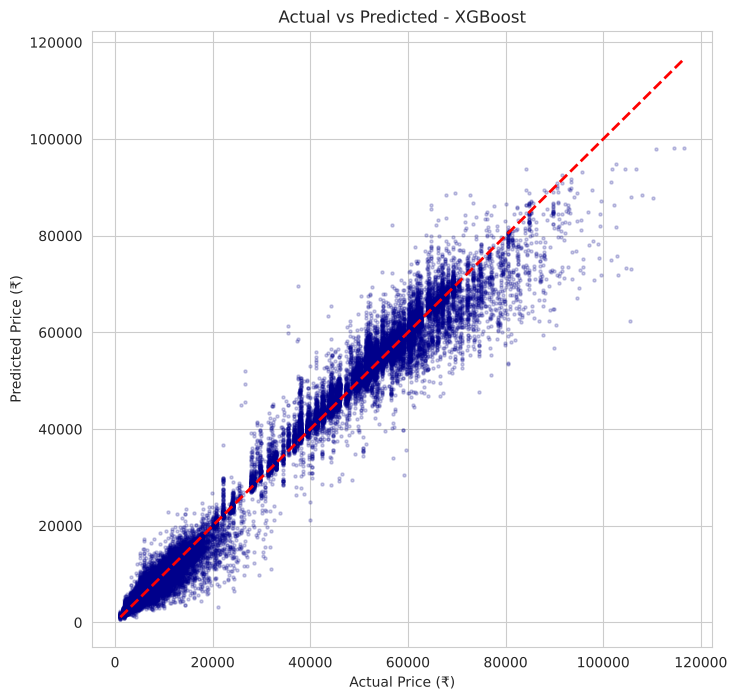

In [30]:
best = results_df.iloc[0]['Model']
print("Best model:", best)

plt.figure(figsize=(8, 8))
plt.scatter(y_test, predictions[best], alpha=0.2, s=5, color='darkblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price (₹)')
plt.ylabel('Predicted Price (₹)')
plt.title(f'Actual vs Predicted - {best}')
plt.show()

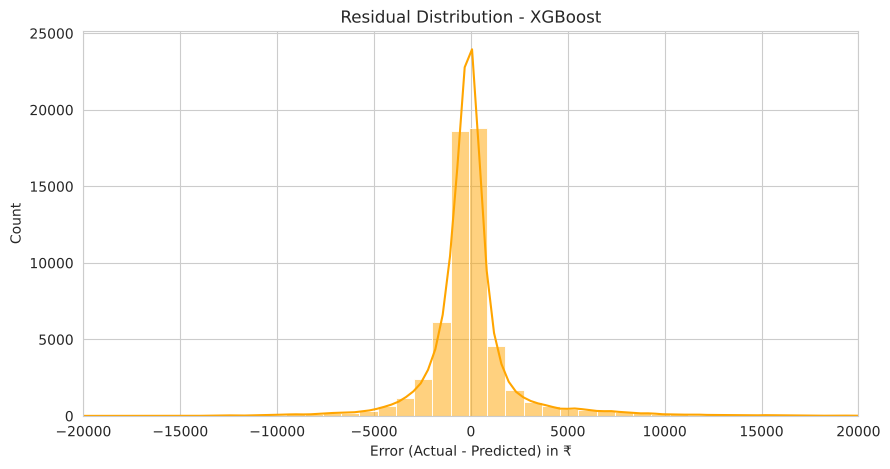

In [31]:
residuals = y_test - predictions[best]
plt.figure(figsize=(10,5))
sns.histplot(residuals, bins=80, kde=True, color='orange')
plt.title(f'Residual Distribution - {best}')
plt.xlabel('Error (Actual - Predicted) in ₹')
plt.xlim(-20000, 20000)
plt.show()

## 10. Feature Importance

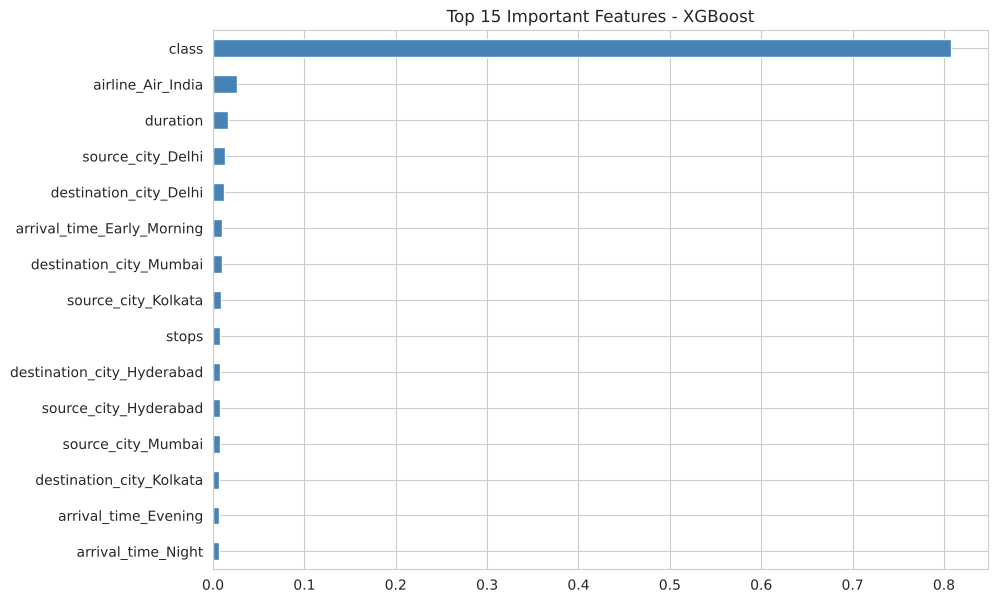

In [32]:
fi = pd.Series(models[best].feature_importances_, index=X.columns).sort_values().tail(15)
fi.plot(kind='barh', figsize=(10, 7), color='steelblue')
plt.title(f'Top 15 Important Features - {best}')
plt.show()

## 11. Sample Predictions

In [33]:
sample_X = X_test.iloc[:8]
pred = models[best].predict(scaler.transform(sample_X))
pd.DataFrame({'Actual Price (₹)': y_test.iloc[:8].values,
              'Predicted Price (₹)': pred.round(0),
              'Difference': (y_test.iloc[:8].values - pred).round(0)})

,Actual Price (₹),Predicted Price (₹),Difference
0,4629,"5,127.0000",-498.0000
1,12166,"11,778.0000",388.0000
2,2022,"2,671.0000",-649.0000
3,2150,"2,150.0000",0.0000
4,60260,"61,120.0000",-860.0000
5,2250,"2,772.0000",-522.0000
6,50271,"50,231.0000",40.0000
7,74844,"71,792.0000","3,052.0000"


## 12. Conclusion

- The dataset had **3,00,153 flight records** of 6 airlines between 6 metro cities. It had no missing values; we removed extreme duration outliers and used the cleaned data for modelling.
- **Class** (Economy/Business) is the biggest factor — business tickets cost ~8-9x more.
- **Days left** matters a lot — booking in the last 1-2 weeks makes tickets much costlier.
- Non-stop and late night flights are generally cheaper. Vistara & Air India are costliest, AirAsia & Indigo cheapest.
- Linear models only reach ~90% R² because the relationships (like days left vs price) are not linear.
- Tree based ensemble models performed best — **XGBoost and Random Forest gave ~98% R² score** with much lower MSE/RMSE.
- Cross validation scores are close to test scores, so the models are stable and not overfitting badly.

**Future scope:** Hyperparameter tuning with GridSearchCV, trying LightGBM / CatBoost, and deploying the model as a web app using Streamlit where a user can enter flight details and get the predicted price.